<p align="center">
  <span style="font-size:32px"><b>ISEL</b></span><br>
  <span style="font-size:26px"><b>Departamento de Engenharia Informática</b></span><br>
  <span style="font-size:24px"><b>Licenciatura em Engenharia Informática e Multimédia</b></span><br>
  <span style="font-size:22px"><b>Processamento de Imagem e Visão</b></span><br><br>
  <span style="font-size:20px"><b>Trabalho Prático 2</b></span><br>
  <span style="font-size:16px">Semestre de Inverno 2026/2027</span><br><br>
  <span style="font-size:16px">Docente: Prof. Pedro Jorge</span><br>
  <span style="font-size:16px">Data: Dezembro 2026</span><br><br>
  <span style="font-size:18px"><b>Trabalho realizado por:</b></span><br>
  <span style="font-size:16px">Beatriz Jesus nº52749</span><br>
  <span style="font-size:16px">Diana Oliveira nº52651</span><br>
</p>

<span style="font-size:19px"><b>Bibliotecas</b></span>

<span style="font-size:16px">Importações de Bibliotecas necessárias para a Implementação do Trabalho:<br></span>

<ul style="font-size:16px">
  <li><b>OpenCV</b> (<code>cv2</code>): Utilizada para processamento de imagens, visualização gráfica de sinais no domínio do tempo e análise visual.</li>
  <li><b>NumPy</b> (<code>numpy</code>): Utilizada para operações numéricas.</li>
  <li><b>Matplotlib</b> (<code>matplotlib.pyplot</code>): Utilizada para Visualização Grafica de Sinais no Domínio do Tempo e apoio à análise dos resultados.</li>

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

A amostragem de frames deve ser espaçada por causa dos objetos, que entram e saiem. Em frames consecutivos, estes objetos apareceriam várias vezes e dominariam a mediana, podendo ser considerados como fundo. Para a mediana funcionar, cada pixel deve ver o fundo em mais de 50% das amostras.


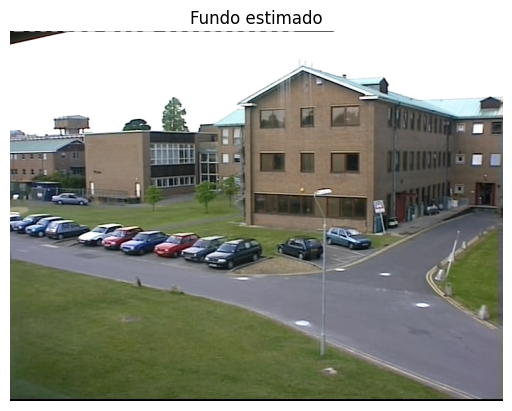

In [2]:
# 1. Estimação de imagem de fundo

def estimar_fundo(caminho_video, n_frames=50):
    video = cv2.VideoCapture(caminho_video)
    total = int(video.get(cv2.CAP_PROP_FRAME_COUNT)) #num total de frames
    # Escolhe n_frames (os seus índices) espaçados uniformemente ao longo do vídeo
    indices = np.linspace(0, total - 1, n_frames).astype(int)

    frames = []
    for i in indices:
        # vai buscar ao vídeo os frames cujos índices foram escolhidos, um de cada vez
        video.set(cv2.CAP_PROP_POS_FRAMES, i)
        # lê-se o frame correspondente à posição esoclhida a cima
        ok, frame = video.read()
        #Se estiver tudo bem, nao houver none, guarda na lista
        if ok:
            frames.append(frame)
    video.release() #fecha o video, ja nao se pode ler dele

    # Mediana ao longo do eixo temporal (axis=0), pixel a pixel
    return np.median(np.stack(frames, axis=0), axis=0).astype(np.uint8)


CAMINHO_VIDEO = "camera1.avi"
fundo = estimar_fundo(CAMINHO_VIDEO, n_frames=50)

cv2.imwrite("fundo.png", fundo)
fundo_rgb = cv2.cvtColor(fundo, cv2.COLOR_BGR2RGB)
plt.imshow(fundo_rgb)
plt.title("Fundo estimado")
plt.axis("off")
plt.show()

. Pos-se os frames a cinzento, porque a deteção de movimento só precisa de intensidade de luz, não de cor, e trabalhar com um único canal simplifica e acelera tudo. 

. É necessário atualizar o fundo, porque o fundo que se estimou no passo 1 é uma fotografia de um momento, e o mundo real muda ao longo do vídeo, por exemplo, a iluminação pode mudar, pode gaver sombras e reflexos que mudam, um carro pode sair do estacionamento, etc. Se o fundo ficar fixo, a imagem de referência vai ficando desatualizada e a subtração começa a dar falsos positivos.

. A máscara tem branco (255) onde há movimento. A dilatação engorda essas zonas brancas em ~7 píxeis para cada lado. Serve de margem de segurança: as bordas de uma pessoa ou carro costumam ser mal detetadas (a máscara fica um pouco mais pequena que o objeto real), e sem a margem esses píxeis de borda seriam atualizados no fundo, deixando um rasto fantasma.



Porquê o desfoque gaussiano no fundo e no frame?

Cada frame tem ruído (do sensor e da compressão do vídeo), por isso píxeis que deviam ser iguais ao fundo variam uns valores para cima ou para baixo. Sem desfoque, alguns desses píxeis ultrapassam o LIMIAR e aparecem na máscara como pontos brancos soltos, que não são movimento. O desfoque faz a média de cada píxel com os vizinhos e atenua esse ruído (slides 6 e 7 do capítulo 5).

Os dois têm de ter o mesmo tratamento. O fundo vem de uma mediana de muitos frames, que sai mais limpa do que um frame isolado. Se só um deles fosse desfocado, a diferença apanhava também a diferença de nitidez entre ambos, e não só o movimento.

Se o desfoque for demasiado forte, os contornos dos objetos ficam menos definidos. 

A máscara original dos carros parados estava picotada: cada píxel ligava e desligava de frame para frame. Com contador[mascara == 0] = 0, bastava um píxel falhar um frame para o contador voltar a zero, e quase nenhum chegava a 100.

A dilatação 15×15 tapa esses buracos. Dentro de uma mancha picotada, todos os píxeis ficam ativos na máscara dilatada de forma contínua, por isso o contador sobe sem reiniciar e a absorção acaba por acontecer. Ou seja, a dilatação tem que ser feita logo ao inicio para preencher esses buracos.

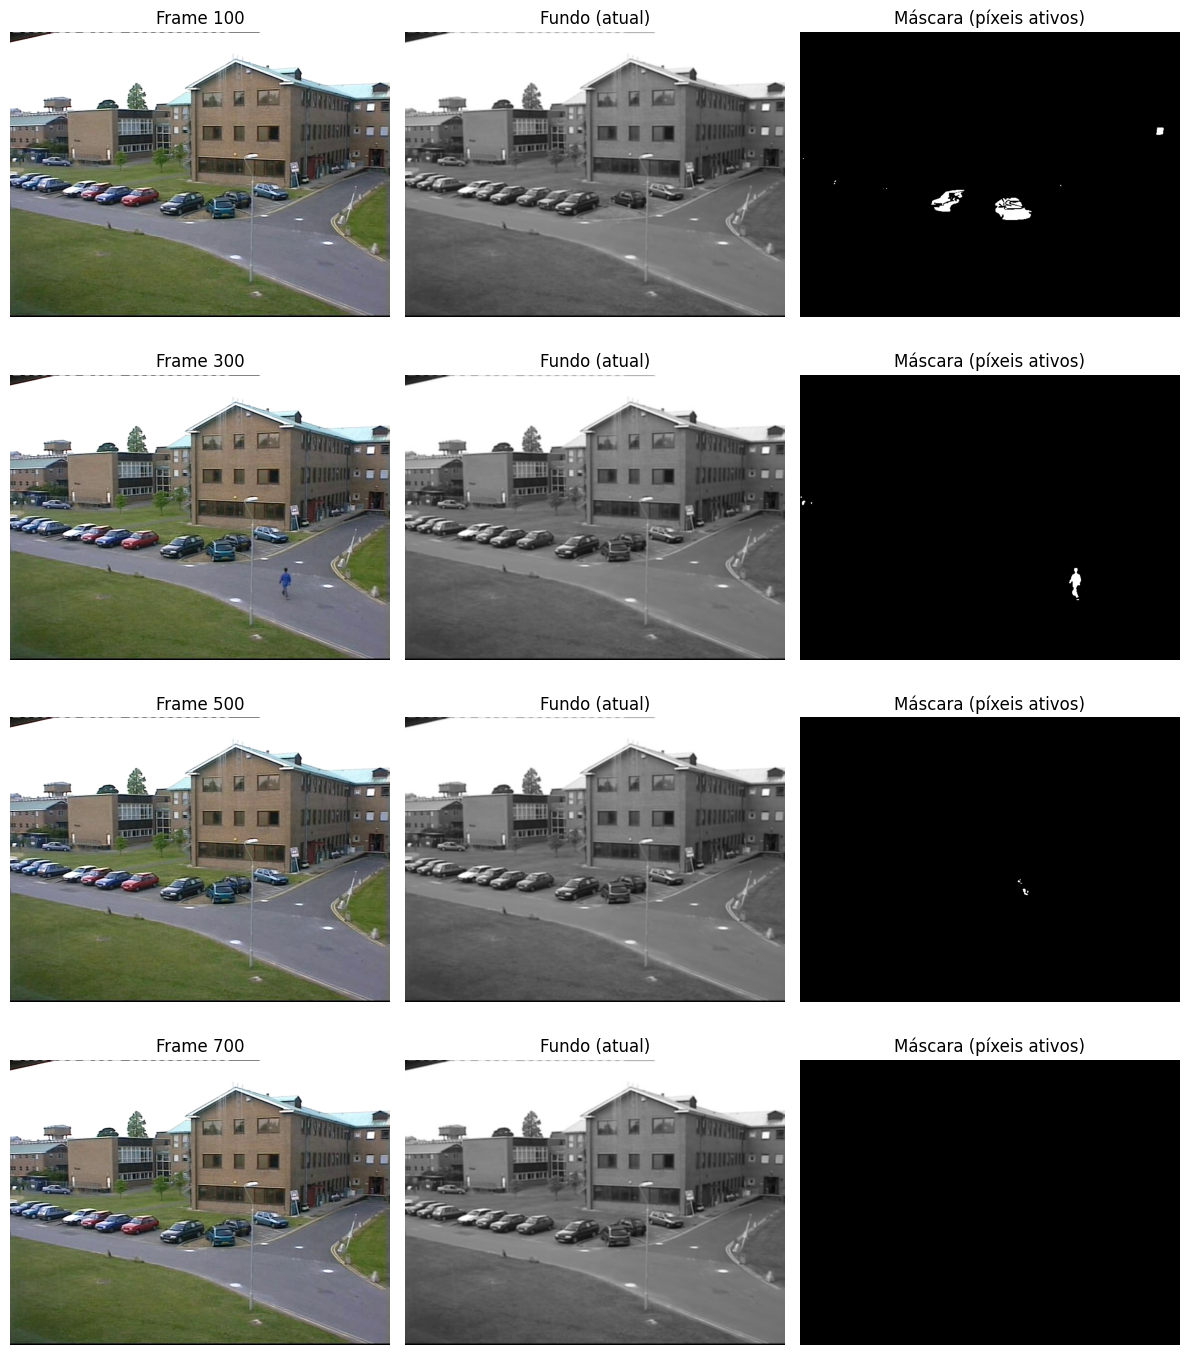

In [3]:
# 2. Deteção de píxeis ativos através da binarização e atualização do fundo

def detetar_pixeis_ativos(gray, fundo_g, limiar=30):
    """Devolve a máscara binária dos píxeis diferentes do fundo."""
    fundo_u8 = fundo_g.astype(np.uint8)  #passou-se para int8 porque abdsdiff precisa de ter o mesmo tipo de dados e gray está a int 8 
    diff = cv2.absdiff(gray, fundo_u8)    # |frame - fundo|
    _, mascara = cv2.threshold(diff, limiar, 255, cv2.THRESH_BINARY) #binarização, limiarização
    return mascara



def atualizar_fundo(fundo_g, gray, mascara,contador, alpha=0.99, n_parado=100, alpha_parado=0.95 ):
    """Atualiza o fundo só nos píxeis SEM movimento: fundo = α·fundo + (1-α)·frame."""
    
    # Dilatar a máscara para proteger também as bordas dos objetos
    mascara_larga = cv2.dilate(mascara, np.ones((15, 15), np.uint8))

    # contador de frames consecutivos ativos, por píxel
    contador[mascara_larga > 0] += 1
    contador[mascara_larga == 0] = 0

    #Atualização normal
    #inverter a máscara, para o fundo ficar a branco, pois é o que queremos atualizar
    so_fundo = cv2.bitwise_not(mascara_larga)

    #atualiza o fundo, misturando uma pequena parte do frame atual nele, mas só nos píxeis onde so_fundo é branco.
    #o alpha do open cv pesa o frame novo, por isso, passa-se 1-alpha, pois alpha=0.99 é do fundo. 
    cv2.accumulateWeighted(gray, fundo_g, 1-alpha, mask=so_fundo)

    # Se houver píxeis parados há muito tempo (ha mais de 100 frames) serão considerados pelo fundo
    parados = ((contador > n_parado) * 255).astype(np.uint8)
    cv2.accumulateWeighted(gray, fundo_g, 1 - alpha_parado, mask=parados)
    # O contador guarda, para cada píxel, há quantos frames seguidos está ativo (a branco na máscara). Quando um píxel passa de 100 frames seguidos, 
    # começa a ser atualizado no fundo com alpha_parado. Um carro parado tem muitos píxeis nessa situação, por isso, na prática, o carro inteiro acaba por ser absorvido. Mas cada píxel é avaliado por si.



LIMIAR = 30
ALPHA = 0.99 
video = cv2.VideoCapture(CAMINHO_VIDEO)
total = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

# fundo em cinzentos + desfoque, em float32 (obrigatório para o accumulateWeighted)
fundo_gray = cv2.cvtColor(fundo, cv2.COLOR_BGR2GRAY)
fundo_g = cv2.GaussianBlur(fundo_gray, (5, 5), 0).astype(np.float32)
contador = np.zeros(fundo_g.shape, dtype=np.int32) #contador de frames em que cada pixel esta ativo

frames_a_mostrar = [100, 300, 500, 700]
resultados = []


n = 0
while True:
    ok, frame = video.read()
    if not ok:
        break

    # o frame tem de passar a cinzentos e ser desfocado, tal como o fundo
    gray = cv2.GaussianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (5, 5), 0)

    #objetos com moviento ficam a branco e o fundo a preto
    mascara = detetar_pixeis_ativos(gray, fundo_g, LIMIAR)
    
    atualizar_fundo(fundo_g, gray, mascara, contador, ALPHA)

    if n in frames_a_mostrar:
        resultados.append((n, frame.copy(), fundo_g.astype(np.uint8), mascara))
    n += 1
video.release()


#para mostrar
fig, eixos = plt.subplots(len(resultados), 3, figsize=(12, 3.5 * len(resultados)))
for linha, (n, frame, fundo_atual, mascara) in zip(np.atleast_2d(eixos), resultados):
    linha[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); linha[0].set_title(f"Frame {n}")
    linha[1].imshow(fundo_atual, cmap="gray");               linha[1].set_title("Fundo (atual)")
    linha[2].imshow(mascara, cmap="gray");                   linha[2].set_title("Máscara (píxeis ativos)")
    for ax in linha:
        ax.axis("off")
plt.tight_layout()
plt.show()

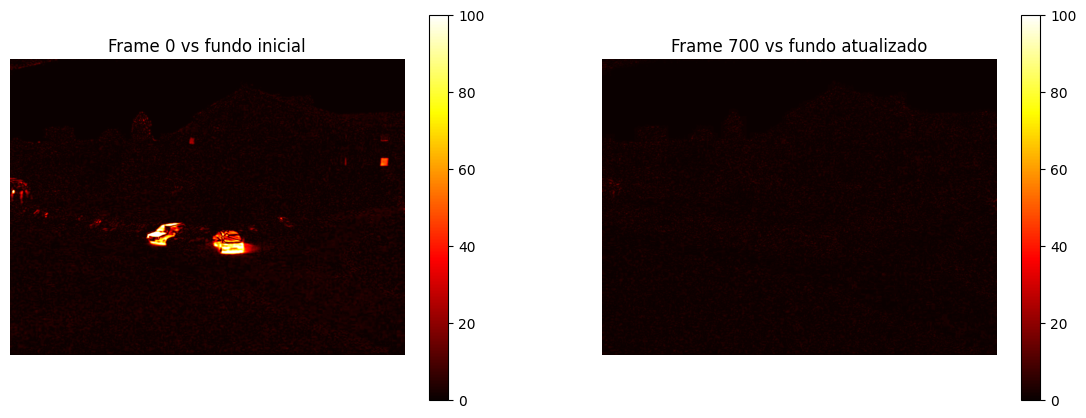

In [4]:
# SÓ PARA ENTENDER O PROBLEMA:
# Diagnóstico: quão diferente é cada píxel do fundo? (mapa de calor)
video = cv2.VideoCapture(CAMINHO_VIDEO)
ok, f0 = video.read()
video.release()

g0 = cv2.GaussianBlur(cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY), (5, 5), 0)
fundo_inicial = cv2.GaussianBlur(cv2.cvtColor(fundo, cv2.COLOR_BGR2GRAY), (5, 5), 0)

n_ult, frame_ult, fundo_ult, _ = resultados[-1]
g_ult = cv2.GaussianBlur(cv2.cvtColor(frame_ult, cv2.COLOR_BGR2GRAY), (5, 5), 0)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for ax, img, titulo in zip(eixos,
        [cv2.absdiff(g0, fundo_inicial), cv2.absdiff(g_ult, fundo_ult)],
        ["Frame 0 vs fundo inicial", f"Frame {n_ult} vs fundo atualizado"]):
    im = ax.imshow(img, cmap="hot", vmin=0, vmax=100)
    ax.set_title(titulo); ax.axis("off")
    plt.colorbar(im, ax=ax)
plt.show()

A ordem é a do algoritmo simples do Cap. 7 (slide 4): componentes conexos, remoção de regiões pequenas, fecho e bounding box. Cada passo serve para preparar o seguinte.

1. Componentes conexos (connectedComponentsWithStats)

Para que serve: agrupa os píxeis brancos que estão ligados entre si (vizinhança 8) em regiões separadas, e dá a cada uma um rótulo, uma área, uma bounding box e um centroide.

Porque vem primeiro: a máscara é só uma imagem de 0 e 255. Para decidir o que é ruído e o que é objeto, é preciso primeiro saber quais são as "manchas" e qual o tamanho de cada uma.

2. Remoção de regiões de área pequena (area_min)

Para que serve: apaga as regiões com menos de area_min píxeis. São o ruído que sobrou da subtração de fundo (píxeis soltos, como os do frame 500). Isto corresponde ao Cap. 5 (slide 5), remoção de componentes conexos de área pequena, e ao passo 3 do slide 4 do Cap. 7.

Porque vem antes do fecho: assim o fecho não liga ruído a objetos reais. Se o fecho viesse primeiro, píxeis soltos perto de um objeto podiam ser fundidos com ele e aumentar a caixa.

3. Fecho morfológico (MORPH_CLOSE com disco)

Para que serve: o fecho é uma dilatação seguida de uma erosão. Preenche buracos pequenos dentro dos objetos e liga partes próximas do mesmo objeto. Na tua máscara, a pessoa e os carros ficam por vezes "picotados", e o fecho transforma-os numa região compacta.

Porque vem depois da remoção de ruído: só deve atuar sobre regiões que já sabemos que são candidatas a objeto.

Cuidado com o k_fecho: um disco grande liga mais, mas pode fundir objetos próximos, como uma pessoa a sair de um carro.

4. Segunda extração de componentes

Para que serve: o fecho pode ter juntado regiões, por isso as áreas, os centroides e as bounding boxes têm de ser calculados sobre a máscara final. Se usasses os valores do passo 1, as caixas não corresponderiam ao que o fecho produziu.

Propriedades extraídas:

Área (número de píxeis da região). É o tamanho da região, vem dos componentes conexos. Separa objetos grandes de pequenos (um carro tem mais píxeis do que uma pessoa) e serve para eliminar ruído. No passo 6 é o critério auxiliar. Foi calculado no passo 4 e reutilizado no passo 5.

Bounding box (x, y, largura, altura). É o retângulo que contém a região. É o que se desenha e o que dá a largura e a altura para a razão. Também permite o IoU no passo 7, que o enunciado sugere. Foi calculado no passo 4 e reutilizado no passo 5.

Centroide. É o centro da região. A distância entre centroides em frames consecutivos é um critério de correspondência do passo 7 e dá a trajetória (o rasto pedido no enunciado). Foi calculado no passo 4 e reutilizado no passo 5.


Razão largura/altura (w / h). É a forma da caixa. Menor que 1 é alta, maior que 1 é larga. Uma pessoa de pé tem a caixa mais alta do que larga e um carro visto de lado tem-na mais larga. É a propriedade que mais separa as duas classes. Ao contrário da área, não depende (tanto) da distância à câmara. Feito no passo 5, reutilizado do 1º trabalho.

Retangularidade (área / (w · h)). A fração da caixa que está realmente preenchida. Uuma região compacta (um carro) tem extensão alta, enquanto uma forma irregular ou com membros afastados tem extensão mais baixa. É um apoio opcional para casos ambíguos. Feito no passo 5, reutilizado do 1º trabalho.

Histograma de cor (H e S). É a distribuição das cores dentro da região, com 16 bins em H e 16 em S, normalizada pelo número de píxeis. Descreve a aparência do objeto e serve para decidir qual região corresponde a qual objeto no passo 7, comparando com a distância L1.
Porquê H e S: são independentes da luminosidade (o V fica de fora), o que torna o histograma menos sensível a sombras e a variações de iluminação. É o ponto 3 do enunciado.
Porquê normalizar: para duas regiões de tamanhos diferentes serem comparáveis.
Porquê dentro da máscara: para o histograma contar só o objeto e não o fundo que cabe na caixa.

Edgeness (fração de píxeis com |∇I| ≥ T). É a densidade de contornos dentro da região, ou seja, uma medida de textura. Uma pessoa e um carro podem ter densidades de contorno diferentes (um carro tem vidros, jantes e matrículas). É uma característica extra para classificar se as regras sobre a forma não chegarem.
Como: o gradiente é calculado com o operador de Sobel, e a fração é contada só dentro da máscara.

Porque estas e não outras:
Poucas e baratas. O enunciado fala de videovigilância, por isso interessam propriedades rápidas de calcular em cada frame.
Cada uma tem um destino. A forma e a área servem a classificação, e o centroide, a bbox e a cor servem a correspondência.

A classificação das regiões é feita com regras sobre a razão largura/altura da bounding box e sobre a área. A razão é o critério principal, por depender pouco da distância à câmara: regiões mais altas do que largas (razão ≤ 0,8) e de área moderada são classificadas como PESSOA; regiões mais largas do que altas (razão ≥ 1,1) e de área elevada são classificadas como CARRO; as restantes ficam em OUTRA. Os limiares foram escolhidos a partir da forma esperada de cada classe e verificados nas regiões detetadas, e a faixa intermédia de razão fica em OUTRA para evitar decisões em casos ambíguos. Esta abordagem não vem da matéria das aulas; a edgeness e a extensão foram testadas mas não discriminavam as classes nos exemplos observados.

O passo 7, a correspondencia,  usou-se Cap. 7, slide 6( search rectangle + match + vetor de movimento);
(slides 12-13: distância entre histogramas)



=== Frame 100: 3 regiões ===
  Região 0: bbox=(720, 193, 15, 15)  área=196  centroide=(727.0, 199.8)  razão l/a=1.00  retangularidade=0.87  edgeness=0.55
  Região 1: bbox=(265, 319, 67, 44)  área=1566  centroide=(296.7, 340.9)  razão l/a=1.52  retangularidade=0.53  edgeness=0.57
  Região 2: bbox=(394, 335, 74, 45)  área=2194  centroide=(426.9, 359.7)  razão l/a=1.64  retangularidade=0.66  edgeness=0.81

=== Frame 300: 1 regiões ===
  Região 0: bbox=(544, 390, 24, 60)  área=705  centroide=(556.3, 418.1)  razão l/a=0.40  retangularidade=0.49  edgeness=0.75

=== Frame 500: 0 regiões ===

=== Frame 700: 0 regiões ===


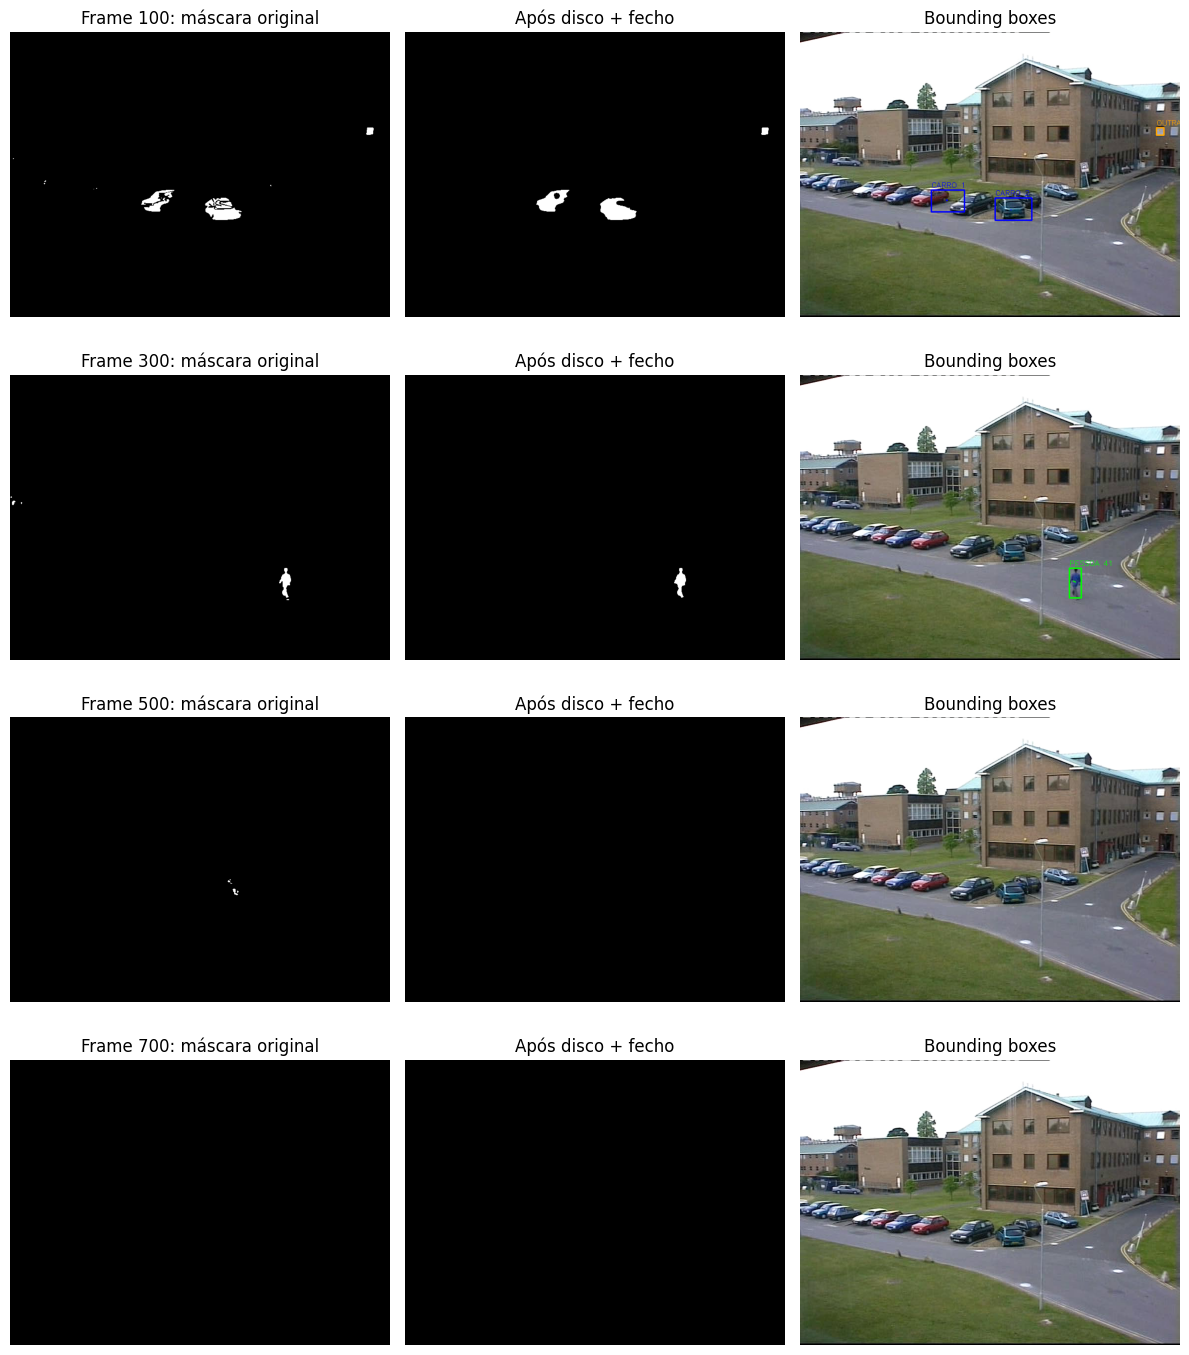

In [5]:
# 3. Operadores morfológicos para remover ruído e preencher falhas (só limpa a máscara)
def limpar_mascara(mascara, area_min=150, k_fecho=9):

    # Passos 1 e 2: componentes conexos e remoção de regiões de área pequena
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)

    sem_ruido = np.zeros_like(mascara)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= area_min:
            sem_ruido[labels == i] = 255

    # Passo 3: fecho com disco pequeno (preenche buracos, liga partes do mesmo objeto)
    disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_fecho, k_fecho))
    fecho = cv2.morphologyEx(sem_ruido, cv2.MORPH_CLOSE, disco)

    return fecho


# 4. Deteção de regiões ativas (componentes conexos + bounding box)
def detetar_regioes(mascara_limpa):
    #encontra as manchas brancas que estão separadas umas das outras, dentro da própria máscara, e guarda, para cada uma, a caixa que a envolve,
    # a área e o centro.
    
    # Corre uma análise de componentes conexas sobre a máscara binária: agrupa os píxeis brancos que estão ligados entre si e dá a cada grupo um número (uma etiqueta). 
    # connectivity=8 quer dizer que dois píxeis contam como ligados também na diagonal (com 4, só contariam acima/abaixo/esquerda/direita). 
    # Devolve quatro coisas:
    # n: número de componentes incluindo o fundo. Se houver 3 objetos, n vale 4.
    # labels: imagem do mesmo tamanho da máscara em que cada píxel tem o número da componente a que pertence (0 para o fundo, 1, 2, 3... para as manchas).
    # stats: tabela com uma linha por componente e 5 colunas: x, y, largura, altura, área da caixa que a envolve (x e y são o canto superior esquerdo; a área é o número de píxeis brancos da componente).
    # centroides: tabela com uma linha por componente e 2 colunas: (x, y) do centro de massa. 

    # Passo 4: nova extração de componentes, para bounding boxes e centroides pós-fecho
    n, labels, stats, centroides = cv2.connectedComponentsWithStats(mascara_limpa, connectivity=8)
    
    regioes = []
    #Percorre todas as componentes de 1 até n-1. Começa em 1 porque a etiqueta 0 é sempre o fundo preto, que não interessa.
    for i in range(1, n):                       # 0 é o fundo
        x, y, w, h, area = (int(v) for v in stats[i]) #tira as medidas de cda regiao
        regioes.append({"bbox": (x, y, w, h), "area": area,
                        "centroide": (float(centroides[i][0]), float(centroides[i][1]))}) #Cria um dicionário com a informação dessa região e junta-o à lista
    return regioes


# 5. Extração de propriedades das regiões
def extrair_propriedades(regioes, frame, mascara_limpa, T_edge=40, bins=16):
    """Acrescenta a cada região: razão l/a, extensão, histograma de cor (H, S) e edgeness."""

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # Gradiente do frame em cinzentos (Sobel, Cap. 5 slide 15): magnitude |∇I|
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(gx, gy)

    for r in regioes:
        x, y, w, h = r["bbox"]
        roi_mask = mascara_limpa[y:y + h, x:x + w]       # só os píxeis da região
        n_pix = int((roi_mask > 0).sum())

        # Geometria (1º trabalho)
        r["razao"] = w / h
        r["retangularidade"] = r["area"] / (w * h)

        # Histograma de cor normalizado (Cap. 6, slide 10): H e S dentro da máscara
        roi_hsv = hsv[y:y + h, x:x + w]
        hist_h = cv2.calcHist([roi_hsv], [0], roi_mask, [bins], [0, 180]).flatten()
        hist_s = cv2.calcHist([roi_hsv], [1], roi_mask, [bins], [0, 256]).flatten()
        r["hist"] = np.concatenate([hist_h, hist_s]) / max(n_pix, 1)

        # Edgeness (Cap. 6, slide 16): fração de píxeis com |∇I| >= T
        mag = magnitude[y:y + h, x:x + w]
        r["edgeness"] = float(((mag >= T_edge) & (roi_mask > 0)).sum()) / max(n_pix, 1)
    return regioes

def distancia_hist(h1, h2):
    """Distância L1 entre histogramas (Cap. 6, slide 10)."""
    return float(np.abs(h1 - h2).sum())



# 6. Classificação das regiões

RAZAO_PESSOA_MAX = 0.8     # l/a abaixo disto -> forma alta
RAZAO_CARRO_MIN = 1.1      # l/a acima disto  -> forma larga
AREA_PESSOA = (150, 2500)  # intervalo de áreas para pessoa
AREA_CARRO_MIN = 800       # área mínima para carro

CORES = {"PESSOA": (0, 255, 0), "CARRO": (255, 0, 0), "OUTRA": (0, 165, 255)}   # BGR

def classificar_regioes(regioes):
    for r in regioes:
        razao, area = r["razao"], r["area"]
        if razao <= RAZAO_PESSOA_MAX and AREA_PESSOA[0] <= area <= AREA_PESSOA[1]:
            r["classe"] = "PESSOA"
        elif razao >= RAZAO_CARRO_MIN and area >= AREA_CARRO_MIN:
            r["classe"] = "CARRO"
        else:
            r["classe"] = "OUTRA"
    return regioes




# 7. Correspondência entre regiões detetadas em imagens consecutivas

MARGEM = 60      # folga (px) à volta da bbox anterior: o "search rectangle"
HIST_MAX = 1.0   # match "bom" se a distância L1 entre histogramas <= HIST_MAX (0 a 4)
#L1 é uma maneira de medir a distância entre dois vetores (listas de números): somas as diferenças, em valor absoluto, posição a posição.

def na_janela(r_ant, r_atual, margem=MARGEM):
    """O centroide da região atual cai dentro do search rectangle da anterior?"""
    x, y, w, h = r_ant["bbox"]
    cx, cy = r_atual["centroide"]
    return (x - margem <= cx <= x + w + margem) and (y - margem <= cy <= y + h + margem)


def associar_regioes(regioes_ant, regioes_atuais, proximo_id):
    # 1) pares candidatos: dentro da janela de pesquisa e com match de cor bom
    pares = []
    for i, ra in enumerate(regioes_ant):
        for j, rb in enumerate(regioes_atuais):
            if not na_janela(ra, rb):
                continue
            d_hist = distancia_hist(ra["hist"], rb["hist"])
            if d_hist > HIST_MAX:
                continue
            dist = np.hypot(ra["centroide"][0] - rb["centroide"][0],
                            ra["centroide"][1] - rb["centroide"][1])
            pares.append((dist / MARGEM + d_hist / HIST_MAX, i, j))

    # 2) atribuir pelo menor custo, sem repetir regiões
    usados_ant, usados_atual = set(), set()
    for custo, i, j in sorted(pares):
        if i in usados_ant or j in usados_atual:
            continue
        ra, rb = regioes_ant[i], regioes_atuais[j]
        rb["id"] = ra["id"]
        # vetor de movimento: cauda = centroide anterior, cabeça = centroide atual
        rb["vetor"] = (rb["centroide"][0] - ra["centroide"][0],
                       rb["centroide"][1] - ra["centroide"][1])
        usados_ant.add(i)
        usados_atual.add(j)

    # 3) sem correspondência -> objeto novo
    for j, rb in enumerate(regioes_atuais):
        if j not in usados_atual:
            rb["id"] = proximo_id
            rb["vetor"] = (0.0, 0.0)
            proximo_id += 1
    return proximo_id







AREA_MIN = 150
K_FECHO = 9

video = cv2.VideoCapture(CAMINHO_VIDEO)
fundo_gray = cv2.cvtColor(fundo, cv2.COLOR_BGR2GRAY)
fundo_g = cv2.GaussianBlur(fundo_gray, (5, 5), 0).astype(np.float32)
contador = np.zeros(fundo_g.shape, dtype=np.int32)

frames_a_mostrar = [100, 300, 500, 700]
resultados = []
regioes_ant = []
proximo_id = 0
n = 0

while True:
    ok, frame = video.read()
    if not ok:
        break

    gray = cv2.GaussianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    mascara = detetar_pixeis_ativos(gray, fundo_g, LIMIAR)
    atualizar_fundo(fundo_g, gray, mascara, contador, ALPHA)

    # O fundo é atualizado com a máscara original; a limpeza só serve para as regiões
    limpa = limpar_mascara(mascara)          # 3. Operados Morfológicos
    regioes = detetar_regioes(limpa)         # 4. Deteção de regiões ativas
    propriedades = extrair_propriedades(regioes, frame, limpa)     # 5. Extração de propriedades das regiões
    classsificacoes = classificar_regioes(regioes)               # 6. Classificação das regiões
    proximo_id = associar_regioes(regioes_ant, regioes, proximo_id)   #7. Correspondência entre regiões detetadas em imagens consecutivas
    regioes_ant = regioes

    if n in frames_a_mostrar:

        # Mostrar propriedades 
        print(f"\n=== Frame {n}: {len(regioes)} regiões ===")
        for i, r in enumerate(regioes):
            print(f"  Região {i}: bbox={r['bbox']}  área={r['area']}  "
                  f"centroide=({r['centroide'][0]:.1f}, {r['centroide'][1]:.1f})  "
                  f"razão l/a={r['razao']:.2f}  retangularidade={r['retangularidade']:.2f}  "
                  f"edgeness={r['edgeness']:.2f}")

        vis = frame.copy()
        for r in regioes:
            x, y, w, h = r["bbox"]
            cor = CORES[r["classe"]]
            cv2.rectangle(vis, (x, y), (x + w, y + h), cor, 2)
            cx, cy = map(int, r["centroide"])
            vx, vy = r["vetor"]
            cv2.arrowedLine(vis, (cx, cy), (int(cx + 3 * vx), int(cy + 3 * vy)), cor, 2)

            cv2.putText(vis, f"{r['classe']} {r['id']}", (x, y - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, cor, 1)
            
        resultados.append((n, mascara, limpa, vis, regioes))
    n += 1
video.release()


# Prints e visualização
fig, eixos = plt.subplots(len(resultados), 3, figsize=(12, 3.5 * len(resultados)))
for linha, (n, mascara, limpa, vis, regioes) in zip(np.atleast_2d(eixos), resultados):
    linha[0].imshow(mascara, cmap="gray"); linha[0].set_title(f"Frame {n}: máscara original")
    linha[1].imshow(limpa, cmap="gray");   linha[1].set_title("Após disco + fecho")
    linha[2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); linha[2].set_title("Bounding boxes")
    for ax in linha:
        ax.axis("off")
plt.tight_layout()
plt.show()


